# Cópula gaussiana frente a cópula t: lo que la correlación no dice sobre la cola

**Perfil:** Riesgo de crédito (estrategia y portafolio)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Dos modelos con las **mismas PD** y la **misma correlación de default** pueden dar pérdidas de cola muy distintas si difieren en la dependencia extrema. ¿Cuánto cambia el capital, y pueden 20–100 años de datos decidir entre ambos modelos?

## Recorrido

1. Mundo verdadero: cópula t con dependencia de cola. Cartera granular homogénea (la tasa de default es función de dos factores).
2. **Versión 1:** cópula gaussiana con la misma correlación de activos.
3. **Diagnóstico:** misma PD, distintas colas; dependencia de cola analítica; ¿qué pasa si se calibra la gaussiana a la correlación de default observable?
4. **Versión 2:** estimar el modelo desde una historia corta por máxima verosimilitud sobre una malla $(\nu,\rho)$.
5. ¿Distinguen los datos entre ambos modelos? Frecuencia de selección y error del capital.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.stats import t as tdist, chi2
from scipy.optimize import brentq

## 2. El modelo

Cada deudor tiene una variable latente de activos $A_i$ y **incumple** si cae por debajo de un umbral. En la **cópula gaussiana**:
$$A_i=\sqrt\rho\,Z+\sqrt{1-\rho}\,\varepsilon_i,\qquad Z,\varepsilon_i\sim N(0,1).$$
En la **cópula t** se multiplica todo por un factor común $\sqrt{\nu/W}$ con $W\sim\chi^2_\nu$: $A^t_i=\sqrt{\nu/W}\,A_i\sim t_\nu$. Ese factor común hace que, cuando $W$ es pequeño, **todos los activos caigan a la vez**: dependencia de cola.

Con infinitos deudores homogéneos la **tasa de default** es una función de los factores comunes:

- Gaussiana: $x=\Phi\!\Big(\dfrac{\Phi^{-1}(\mathrm{PD})-\sqrt\rho\,Z}{\sqrt{1-\rho}}\Big)$.
- t: $x=\Phi\!\Big(\dfrac{t_\nu^{-1}(\mathrm{PD})\sqrt{W/\nu}-\sqrt\rho\,Z}{\sqrt{1-\rho}}\Big)$.

La pérdida es $\mathrm{LGD}\cdot x$ y su cuantil $q$ da el capital.

In [2]:
PD, LGD, Q = 0.02, 0.45, 0.999
RHO_V, NU_V = 0.12, 4                       # el mundo verdadero: copula t con nu=4

def tasa_default(rho, nu, z, w=None):
    # nu=None -> gaussiana
    if nu is None:
        return norm_cdf((norm_ppf(PD) - np.sqrt(rho) * z) / np.sqrt(1 - rho))
    return norm_cdf((tdist.ppf(PD, nu) * np.sqrt(w / nu) - np.sqrt(rho) * z) / np.sqrt(1 - rho))

from scipy.stats import norm
norm_cdf, norm_ppf = norm.cdf, norm.ppf

def simular_x(rho, nu, S, seed):
    rg = np.random.default_rng(seed)
    z = rg.standard_normal(S)
    w = None if nu is None else rg.chisquare(nu, S)
    return tasa_default(rho, nu, z, w)

S_BIG = 1_500_000
x_v = simular_x(RHO_V, NU_V, S_BIG, 1)
x_g_mismo_rho = simular_x(RHO_V, None, S_BIG, 2)
print(f"E[x] (verdadero t): {x_v.mean():.5f} | E[x] (gaussiana): {x_g_mismo_rho.mean():.5f}  (ambas deben ser PD = {PD})")

E[x] (verdadero t): 0.01997 | E[x] (gaussiana): 0.01998  (ambas deben ser PD = 0.02)


## 3. Versión 1: gaussiana con el mismo $\rho$

El analista usa la cópula gaussiana con **el mismo parámetro de correlación de activos** que el mundo verdadero.

In [3]:
def capital(x, q=Q):
    return LGD * (np.quantile(x, q) - x.mean())

niveles = [0.95, 0.99, 0.999, 0.9999]
filas = []
for q in niveles:
    kv, kg = capital(x_v, q), capital(x_g_mismo_rho, q)
    filas.append({"nivel": q, "K_t_verdadero": kv, "K_gaussiana": kg, "gaussiana/verdad": kg / kv})
v1 = pd.DataFrame(filas).set_index("nivel")
v1.round(5)

,K_t_verdadero,K_gaussiana,gaussiana/verdad
nivel,,,
0.9500,0.0398,0.0166,0.4164
0.9900,0.1041,0.0323,0.3106
0.9990,0.1925,0.0570,0.2958
0.9999,0.2600,0.0823,0.3167


In [4]:
print("Lectura:")
print(f"  Con el mismo rho y las mismas PD, la gaussiana da {v1.loc[0.999, 'gaussiana/verdad']:.2f}x el capital verdadero al 99.9% ({v1.loc[0.95, 'gaussiana/verdad']:.2f}x al 95%).")
print(f"  Por nivel de confianza: {', '.join(f'{q}: {r:.2f}x' for q, r in v1['gaussiana/verdad'].items())}.")
print("  Ojo: comparar 'a igual rho' mezcla dos efectos: la t tiene MAS correlacion de default (por la dependencia de cola) y ademas otra forma de cola. La seccion 4.2 los separa.")

Lectura:
  Con el mismo rho y las mismas PD, la gaussiana da 0.30x el capital verdadero al 99.9% (0.42x al 95%).
  Por nivel de confianza: 0.95: 0.42x, 0.99: 0.31x, 0.999: 0.30x, 0.9999: 0.32x.
  Ojo: comparar 'a igual rho' mezcla dos efectos: la t tiene MAS correlacion de default (por la dependencia de cola) y ademas otra forma de cola. La seccion 4.2 los separa.


## 4. Diagnóstico

### 4.1 La dependencia de cola

El coeficiente de dependencia de cola superior de la cópula t es $\lambda=2\,t_{\nu+1}\!\big(-\sqrt{(\nu+1)(1-\rho)/(1+\rho)}\big)$; el de la gaussiana es **0** para cualquier $\rho<1$.

In [5]:
def lambda_cola(rho, nu):
    if nu is None: return 0.0
    return 2 * tdist.cdf(-np.sqrt((nu + 1) * (1 - rho) / (1 + rho)), nu + 1)

tab = pd.DataFrame({f"nu={nu}": [lambda_cola(r, nu) for r in (0.05, 0.12, 0.30)] for nu in (3, 4, 6, 10, 30)}, index=[f"rho={r}" for r in (0.05, 0.12, 0.30)])
tab["gaussiana"] = 0.0
print("Coeficiente de dependencia de cola (probabilidad de que un activo caiga extremo dado que otro cae extremo):")
tab.round(4)

Coeficiente de dependencia de cola (probabilidad de que un activo caiga extremo dado que otro cae extremo):


,nu=3,nu=4,nu=6,nu=10,nu=30,gaussiana
rho=0.05,0.1299,0.0867,0.0400,0.0092,0.0000,0.0000
rho=0.12,0.1509,0.1043,0.0514,0.0135,0.0000,0.0000
rho=0.3,0.2161,0.1618,0.0933,0.0332,0.0003,0.0000


### 4.2 ¿Se arregla calibrando la gaussiana a la correlación de default?

La correlación de $\rho$ de activos no se observa; lo que se **observa** es la correlación de default (la varianza de la tasa de default $x$). Se calibra la gaussiana para que **su varianza de $x$ coincida con la verdadera** y se vuelve a comparar.

In [6]:
var_v = x_v.var()
z_fijo = np.random.default_rng(3).standard_normal(S_BIG)

def var_gauss(rho):
    return tasa_default(rho, None, z_fijo).var()

rho_cal = brentq(lambda r: var_gauss(r) - var_v, 0.01, 0.6)
x_g_cal = tasa_default(rho_cal, None, z_fijo)
corr_default_v = var_v / (PD * (1 - PD))
print(f"Varianza de la tasa de default (verdadera) = {var_v:.6f}  -> correlacion de default = {corr_default_v:.4f}")
print(f"rho gaussiana calibrada a esa varianza = {rho_cal:.4f} (la verdadera de activos era {RHO_V})")
filas = []
for q in niveles:
    kv, kg, kc = capital(x_v, q), capital(x_g_mismo_rho, q), capital(x_g_cal, q)
    filas.append({"nivel": q, "K_t": kv, "gaussiana(rho verdadera)": kg / kv, "gaussiana(calibrada a varianza)": kc / kv})
v1b = pd.DataFrame(filas).set_index("nivel")
v1b.round(4)

Varianza de la tasa de default (verdadera) = 0.002381  -> correlacion de default = 0.1215
rho gaussiana calibrada a esa varianza = 0.4421 (la verdadera de activos era 0.12)


,K_t,gaussiana(rho verdadera),gaussiana(calibrada a varianza)
nivel,,,
0.9500,0.0398,0.4165,0.8971
0.9900,0.1041,0.3106,0.9841
0.9990,0.1925,0.2958,1.1215
0.9999,0.2600,0.3168,1.2015


In [7]:
print("Lectura:")
print(f"  Calibrada a la correlacion de default, la gaussiana pasa de {v1b.loc[0.999, 'gaussiana(rho verdadera)']:.2f}x a {v1b.loc[0.999, 'gaussiana(calibrada a varianza)']:.2f}x del capital verdadero al 99.9%.")
print("  Por nivel de confianza: " + ", ".join(f"{q}: {r:.2f}x" for q, r in v1b["gaussiana(calibrada a varianza)"].items()) + ".")
signo = "SOBRESTIMA" if v1b.loc[0.999, "gaussiana(calibrada a varianza)"] > 1 else "SUBESTIMA"
print(f"  Con esta calibracion la gaussiana {signo} el capital al 99.9% (y {'subestima' if v1b.loc[0.95, 'gaussiana(calibrada a varianza)'] < 1 else 'sobrestima'} al 95%): la DIRECCION del sesgo depende de que se calibre. Una sola correlacion no reproduce a la vez el centro y la cola.")

Lectura:
  Calibrada a la correlacion de default, la gaussiana pasa de 0.30x a 1.12x del capital verdadero al 99.9%.
  Por nivel de confianza: 0.95: 0.90x, 0.99: 0.98x, 0.999: 1.12x, 0.9999: 1.20x.
  Con esta calibracion la gaussiana SOBRESTIMA el capital al 99.9% (y subestima al 95%): la DIRECCION del sesgo depende de que se calibre. Una sola correlacion no reproduce a la vez el centro y la cola.


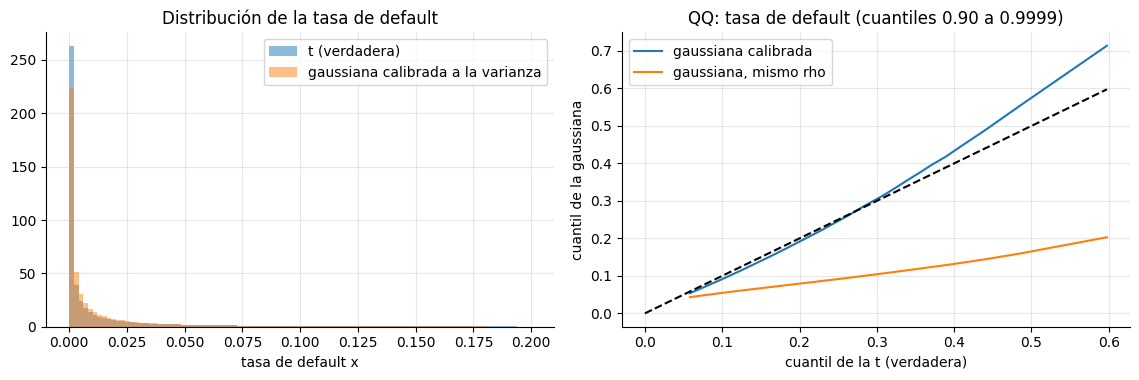

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
bins = np.linspace(0, 0.20, 100)
ax[0].hist(x_v, bins, density=True, alpha=0.5, label="t (verdadera)"); ax[0].hist(x_g_cal, bins, density=True, alpha=0.5, label="gaussiana calibrada a la varianza")
ax[0].set_xlabel("tasa de default x"); ax[0].legend(); ax[0].set_title("Distribución de la tasa de default")
qs = np.linspace(0.9, 0.9999, 200)
ax[1].plot(np.quantile(x_v, qs), np.quantile(x_g_cal, qs), label="gaussiana calibrada")
ax[1].plot(np.quantile(x_v, qs), np.quantile(x_g_mismo_rho, qs), label="gaussiana, mismo rho")
m = np.quantile(x_v, qs).max(); ax[1].plot([0, m], [0, m], "k--"); ax[1].set_xlabel("cuantil de la t (verdadera)"); ax[1].set_ylabel("cuantil de la gaussiana"); ax[1].legend()
ax[1].set_title("QQ: tasa de default (cuantiles 0.90 a 0.9999)")
plt.tight_layout(); plt.show()

## 5. Versión 2: estimar el modelo desde una historia corta

En la práctica no se conoce el mundo verdadero: se tiene una **serie de $T$ tasas de default anuales**. Se hace máxima verosimilitud sobre una **malla** de modelos: $\nu\in\{3,4,6,10,30\}$ más la gaussiana ($\nu=\infty$), y $\rho\in[0{,}02;0{,}40]$.

La densidad de $x$ no tiene forma cerrada para la cópula t. Se usa una **verosimilitud de datos agrupados**: se simulan muchas tasas de cada modelo, se cuenta cuántas caen en cada tramo (en escala probit, con tramos abiertos en ambos extremos para **no perder masa**), y la verosimilitud de la serie observada es la suma de $\log$ de esas probabilidades.

> **Una primera versión de esta sección falló y por eso se deja aquí la validación.** Se había usado un histograma de densidad en escala logit truncado en −12. Un 12 % de las tasas simuladas de la cópula t caen por debajo de ese rango (escenarios benignos con tasa casi cero) y quedaban mal tratadas: con T = 30.000 el estimador eligió un modelo distinto del verdadero, cuya verosimilitud era **mayor** que la del modelo verdadero. Esa imposibilidad estadística fue la señal de que el error estaba en la aproximación, no en los datos. La validación de abajo (recuperar el modelo con T enorme) es lo que lo detecta.

In [9]:
NUS = [3, 4, 6, 10, 30, None]
RHOS = np.round(np.linspace(0.02, 0.60, 30), 4)
BORDES = np.linspace(-9, 2, 301)                         # bordes finitos en escala probit; los tramos extremos son abiertos
S_TAB = 400_000

def a_probit(x):
    return norm.ppf(np.clip(x, 1e-300, 1 - 1e-16))

def tramos(u):
    return np.searchsorted(BORDES, u)                    # 0 = tramo abierto inferior ... len(BORDES) = tramo abierto superior

def construir_tablas(n_obs=None, semilla=1000):
    out = {}
    for i, nu in enumerate(NUS):
        for j, rho in enumerate(RHOS):
            x = simular_x(rho, nu, S_TAB, semilla + 37 * i + j)
            xo = x if n_obs is None else np.random.default_rng(semilla + 91 * i + j).binomial(n_obs, x) / n_obs   # observacion con ruido binomial
            cuentas = np.bincount(tramos(a_probit(xo)), minlength=len(BORDES) + 1).astype(float)
            p = (cuentas + 0.5) / (cuentas.sum() + 0.5 * len(cuentas))          # suavizado para no tener probabilidades cero
            out[(nu, rho)] = {"p": p, "q": np.quantile(x, Q), "media": x.mean(), "var": x.var()}   # q y media son de la tasa LATENTE x
    return out

TABLAS = {None: construir_tablas(None)}
tablas = TABLAS[None]
masa_min = min(t["p"].sum() for t in tablas.values()); masa_max = max(t["p"].sum() for t in tablas.values())
print(f"{len(tablas)} modelos precomputados | masa total por modelo entre {masa_min:.6f} y {masa_max:.6f} (debe ser 1) | rango de varianza de x: {min(t['var'] for t in tablas.values()):.2e} a {max(t['var'] for t in tablas.values()):.2e}")
fuera = np.mean([tablas[(4, 0.12)]["p"][0] + tablas[(4, 0.12)]["p"][-1]])
print(f"Masa del modelo verdadero en los tramos abiertos (fuera de [-9, 2] en probit): {fuera:.1%}")

180 modelos precomputados | masa total por modelo entre 1.000000 y 1.000000 (debe ser 1) | rango de varianza de x: 4.87e-05 a 7.63e-03
Masa del modelo verdadero en los tramos abiertos (fuera de [-9, 2] en probit): 0.0%


In [10]:
def loglik(xobs, nu, rho, n_obs=None):
    p = TABLAS[n_obs][(nu, rho)]["p"]
    return float(np.log(p[tramos(a_probit(xobs))]).sum())

def ajustar_malla(xobs, permitir_t=True, n_obs=None):
    mejor = (-np.inf, None, None)
    for nu in (NUS if permitir_t else [None]):
        for rho in RHOS:
            ll = loglik(xobs, nu, rho, n_obs)
            if ll > mejor[0]: mejor = (ll, nu, rho)
    return mejor

def serie_verdadera(T, seed):
    return simular_x(RHO_V, NU_V, T, seed)

# validacion del estimador: con muchisimos datos debe recuperar el mundo verdadero
xo_grande = serie_verdadera(30_000, 5)
ll, nu_hat, rho_hat = ajustar_malla(xo_grande)
ll_verdad = loglik(xo_grande, NU_V, RHO_V)
print(f"Con T=30.000: nu estimado = {nu_hat}, rho estimado = {rho_hat}  (verdad: nu={NU_V}, rho={RHO_V})")
print(f"Log-verosimilitud del modelo estimado = {ll:.1f} | del verdadero = {ll_verdad:.1f} (el estimado nunca puede quedar por debajo del verdadero, que esta en la malla)")
K_VERDAD = LGD * (np.quantile(x_v, Q) - PD)
k_hat = LGD * (tablas[(nu_hat, rho_hat)]["q"] - tablas[(nu_hat, rho_hat)]["media"])
print(f"Capital verdadero al 99.9% = {K_VERDAD:.5f} | capital con el modelo estimado = {k_hat:.5f} ({k_hat / K_VERDAD - 1:+.1%})")

Con T=30.000: nu estimado = 4, rho estimado = 0.12  (verdad: nu=4, rho=0.12)
Log-verosimilitud del modelo estimado = -145540.5 | del verdadero = -145540.5 (el estimado nunca puede quedar por debajo del verdadero, que esta en la malla)
Capital verdadero al 99.9% = 0.19252 | capital con el modelo estimado = 0.19080 (-0.9%)


Con muchísimos datos, el estimador recupera el mundo verdadero. Pero **la pregunta práctica** es qué pasa con **20–100 años**. Se repite la estimación en 300 historias independientes y se mide (i) qué modelo se elige y (ii) el error del capital resultante, comparado con ajustar **solo** la gaussiana.

In [11]:
def experimento(T, R=300, seed0=0, n_obs=None, modelar_ruido=True):
    # n_obs: numero de deudores observados (None = tasa exacta). modelar_ruido=False usa tablas de tasa exacta (estimador ingenuo)
    tab_clave = n_obs if modelar_ruido else None
    tab = TABLAS[tab_clave]
    filas = []
    for r in range(R):
        xo = serie_verdadera(T, seed0 + r)
        if n_obs is not None:
            xo = np.random.default_rng(10**7 + seed0 + r).binomial(n_obs, xo) / n_obs
        ll_t, nu_h, rho_h = ajustar_malla(xo, True, tab_clave)
        ll_g, _, rho_g = ajustar_malla(xo, False, tab_clave)
        k_libre = LGD * (tab[(nu_h, rho_h)]["q"] - tab[(nu_h, rho_h)]["media"])
        k_gauss = LGD * (tab[(None, rho_g)]["q"] - tab[(None, rho_g)]["media"])
        filas.append({"nu_hat": "inf" if nu_h is None else nu_h, "rho_gauss": rho_g, "razon_K_libre": k_libre / K_VERDAD, "razon_K_gauss": k_gauss / K_VERDAD, "mejora_loglik": ll_t - ll_g})
    return pd.DataFrame(filas)

def resumir(df):
    return {"P(elige t con nu<=6)": df["nu_hat"].map(lambda v: v != "inf" and v <= 6).mean(), "P(elige gaussiana)": float((df["nu_hat"] == "inf").mean()),
            "mediana K libre/verdad": df["razon_K_libre"].median(), "P5 libre": df["razon_K_libre"].quantile(.05), "P95 libre": df["razon_K_libre"].quantile(.95),
            "mediana K gauss/verdad": df["razon_K_gauss"].median(), "P5 gauss": df["razon_K_gauss"].quantile(.05), "P95 gauss": df["razon_K_gauss"].quantile(.95),
            "mediana rho gauss": df["rho_gauss"].median()}

res = {T: experimento(T, seed0=10_000 * T) for T in (20, 40, 100, 400)}
resumen = pd.DataFrame({T: resumir(df) for T, df in res.items()}).T
resumen.round(3)

,P(elige t con nu<=6),P(elige gaussiana),mediana K libre/verdad,P5 libre,P95 libre,mediana K gauss/verdad,P5 gauss,P95 gauss,mediana rho gauss
20,0.6030,0.1370,1.0890,0.7710,1.6030,1.4210,1.0340,1.6030,0.5400
40,0.6570,0.1100,1.0910,0.7710,1.5380,1.4210,1.2290,1.6030,0.5400
100,0.8470,0.0530,1.0410,0.8210,1.4740,1.4740,1.3000,1.6030,0.5600
400,0.9630,0.0130,0.9910,0.9110,1.3300,1.4740,1.3650,1.5380,0.5600


### 5.1 ¿Y con una cartera finita? El ruido binomial de muestreo

Lo anterior observa la tasa de default **exacta** (cartera infinita). Una cartera real tiene $N$ deudores y la tasa observada es $\text{Binomial}(N,x)/N$, que añade ruido. Se repite con $T=40$ años y $N\in\{5.000,\,1.000\}$ comparando **dos estimadores**:

- **ingenuo:** ajusta con las tablas de tasa exacta, ignorando el ruido de muestreo;
- **con ruido modelado:** las tablas simulan la observación binomial.

In [12]:
TABLAS[5000] = construir_tablas(5000, semilla=5000)
TABLAS[1000] = construir_tablas(1000, semilla=9000)
filas = {}
for n in (5000, 1000):
    for modelar in (False, True):
        df = experimento(40, R=150, seed0=777, n_obs=n, modelar_ruido=modelar)
        filas[(f"N={n}", "ruido modelado" if modelar else "ingenuo")] = resumir(df)
resumen_n = pd.DataFrame(filas).T
resumen_n.round(3)

P(elige t con nu<=6)  P(elige gaussiana)  \
N=5000 ingenuo                       1.0000              0.0000   
       ruido modelado                0.6070              0.1070   
N=1000 ingenuo                       1.0000              0.0000   
       ruido modelado                0.6270              0.1070   

                       mediana K libre/verdad  P5 libre  P95 libre  \
N=5000 ingenuo                         2.0730    1.8730     2.0730   
       ruido modelado                  1.0870    0.7620     1.5120   
N=1000 ingenuo                         2.0730    2.0730     2.0730   
       ruido modelado                  1.0540    0.7690     1.5070   

                       mediana K gauss/verdad  P5 gauss  P95 gauss  \
N=5000 ingenuo                         0.8290    0.6350     0.9850   
       ruido modelado                  1.3840    1.0990     1.5870   
N=1000 ingenuo                         0.6350    0.4730     0.8290   
       ruido modelado                  1.2880    1.0870     1.6160   

                       mediana rho gauss  
N=5000 ingenuo                    0.3400  
       ruido modelado             0.5200  
N=1000 ingenuo                    0.2600  
       ruido modelado             0.5000

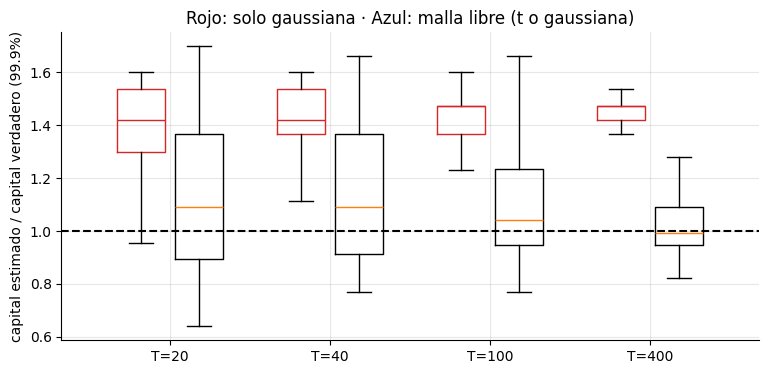

Lectura (cartera infinita, modelo verdadero dentro de la malla):
  La probabilidad de elegir el modelo equivocado (gaussiana) baja de 13.7% con T=20 a 1.3% con T=400.
  Aun asi, el capital estimado por la malla libre va de 0.77x a 1.54x el verdadero (P5-P95) con T=40, y de 0.91x a 1.33x con T=400.
  Ajustar SOLO la gaussiana por maxima verosimilitud da una mediana de 1.42x el capital verdadero (rho gaussiana mediana 0.54, contra 0.12 de activos del mundo t): el ajuste de verosimilitud la lleva a una rho mucho mayor.

Lectura (cartera finita, T=40): capital estimado / verdadero
  N=5000  ingenuo        : malla libre mediana 2.07x (P5-P95 1.87-2.07) | solo gaussiana mediana 0.83x | elige gaussiana 0%
  N=5000  ruido modelado : malla libre mediana 1.09x (P5-P95 0.76-1.51) | solo gaussiana mediana 1.38x | elige gaussiana 11%
  N=1000  ingenuo        : malla libre mediana 2.07x (P5-P95 2.07-2.07) | solo gaussiana mediana 0.64x | elige gaussiana 0%
  N=1000  ruido modelado : malla libre medi

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
pos = np.arange(len(res))
ax.boxplot([res[T]["razon_K_gauss"] for T in res], positions=pos - 0.18, widths=0.3, showfliers=False, boxprops=dict(color="C3"), medianprops=dict(color="C3"))
ax.boxplot([res[T]["razon_K_libre"] for T in res], positions=pos + 0.18, widths=0.3, showfliers=False)
ax.axhline(1, color="k", ls="--"); ax.set_xticks(pos); ax.set_xticklabels([f"T={T}" for T in res]); ax.set_ylabel("capital estimado / capital verdadero (99.9%)")
ax.set_title("Rojo: solo gaussiana · Azul: malla libre (t o gaussiana)"); plt.show()
print("Lectura (cartera infinita, modelo verdadero dentro de la malla):")
print(f"  La probabilidad de elegir el modelo equivocado (gaussiana) baja de {resumen.loc[20, 'P(elige gaussiana)']:.1%} con T=20 a {resumen.loc[400, 'P(elige gaussiana)']:.1%} con T=400.")
print(f"  Aun asi, el capital estimado por la malla libre va de {resumen.loc[40, 'P5 libre']:.2f}x a {resumen.loc[40, 'P95 libre']:.2f}x el verdadero (P5-P95) con T=40, y de {resumen.loc[400, 'P5 libre']:.2f}x a {resumen.loc[400, 'P95 libre']:.2f}x con T=400.")
print(f"  Ajustar SOLO la gaussiana por maxima verosimilitud da una mediana de {resumen.loc[40, 'mediana K gauss/verdad']:.2f}x el capital verdadero (rho gaussiana mediana {resumen.loc[40, 'mediana rho gauss']:.2f}, contra 0.12 de activos del mundo t): el ajuste de verosimilitud la lleva a una rho mucho mayor.")
print()
print("Lectura (cartera finita, T=40): capital estimado / verdadero")
for (n, tipo), r in resumen_n.iterrows():
    print(f"  {n:7s} {tipo:15s}: malla libre mediana {r['mediana K libre/verdad']:.2f}x (P5-P95 {r['P5 libre']:.2f}-{r['P95 libre']:.2f}) | solo gaussiana mediana {r['mediana K gauss/verdad']:.2f}x | elige gaussiana {r['P(elige gaussiana)']:.0%}")

**Qué se aprende.** (i) Con tasas de default exactas y el modelo verdadero dentro de la malla, el ajuste **sí discrimina** la cola. (ii) Esa discriminación se **debilita con ruido de muestreo** (cartera finita). (iii) Aun cuando se elige el modelo correcto, la incertidumbre del capital con 20–100 años es de decenas por ciento. (iv) El resultado depende de que el modelo verdadero esté en la familia que se ajusta: con un modelo mal especificado, la verosimilitud puede preferir un modelo que ordena bien el centro y falla en la cola.

## 6. Robustez y sensibilidad

### 6.1 Sensibilidad del riesgo de modelo a los grados de libertad

In [14]:
filas = []
for nu in (3, 4, 6, 10, 30):
    xt = simular_x(RHO_V, nu, 800_000, 70 + nu)
    # gaussiana calibrada a la misma varianza de x
    zf = np.random.default_rng(9).standard_normal(800_000)
    rg = brentq(lambda r: tasa_default(r, None, zf).var() - xt.var(), 0.01, 0.8)
    xg = tasa_default(rg, None, zf)
    filas.append({"nu": nu, "lambda_cola": lambda_cola(RHO_V, nu), "gauss_calibrada/t al 99.9%": capital(xg, Q) / capital(xt, Q),
                  "gauss_calibrada/t al 99.99%": capital(xg, 0.9999) / capital(xt, 0.9999)})
sens = pd.DataFrame(filas).set_index("nu")
sens.round(4)

,lambda_cola,gauss_calibrada/t al 99.9%,gauss_calibrada/t al 99.99%
nu,,,
3,0.1509,1.1513,1.2535
4,0.1043,1.1216,1.2031
6,0.0514,1.0752,1.1318
10,0.0135,1.0433,1.0594
30,0.0000,1.0107,1.0255


In [15]:
print("Lectura: a medida que nu crece la t converge a la gaussiana y el riesgo de modelo desaparece:")
print("  razon al 99.9% con nu=3:", f"{sens.loc[3, 'gauss_calibrada/t al 99.9%']:.2f}", "| con nu=30:", f"{sens.loc[30, 'gauss_calibrada/t al 99.9%']:.2f}")

Lectura: a medida que nu crece la t converge a la gaussiana y el riesgo de modelo desaparece:
  razon al 99.9% con nu=3: 1.15 | con nu=30: 1.01


### 6.2 Error de Monte Carlo del cuantil

In [16]:
lotes = np.array_split(np.random.default_rng(0).permutation(len(x_v)), 10)
qs_ = np.array([np.quantile(x_v[ix], Q) for ix in lotes])
print(f"Cuantil 99.9% de x en 10 lotes: media {qs_.mean():.5f}, desvio entre lotes {qs_.std():.5f} -> error estandar de la media {qs_.std() / np.sqrt(10):.5f} ({qs_.std() / np.sqrt(10) / qs_.mean():.2%})")

Cuantil 99.9% de x en 10 lotes: media 0.44692, desvio entre lotes 0.00780 -> error estandar de la media 0.00247 (0.55%)


## 7. Pruebas automáticas

In [17]:
# 7.1 las PD marginales se preservan en ambos modelos (la media de x es la PD)
for nu in (3, 4, 10, None):
    assert abs(simular_x(0.15, nu, 600_000, 3).mean() / PD - 1) < 0.03, f"E[x] != PD para nu={nu}"
# 7.2 la t converge a la gaussiana para nu grande
xt_grande = simular_x(RHO_V, 2000, 600_000, 4)
assert abs(capital(xt_grande, 0.99) / capital(x_g_mismo_rho, 0.99) - 1) < 0.08
# 7.3 con el mismo rho la gaussiana subestima fuertemente el capital en todos los niveles
assert (v1["gaussiana/verdad"] < 0.6).all()
# 7.4 la calibracion por varianza iguala la varianza, y cambia la DIRECCION del sesgo entre el centro y la cola
assert abs(x_g_cal.var() / var_v - 1) < 0.01
assert v1b.loc[0.95, "gaussiana(calibrada a varianza)"] < 1 < v1b.loc[0.9999, "gaussiana(calibrada a varianza)"]
assert (v1b["gaussiana(calibrada a varianza)"] > v1b["gaussiana(rho verdadera)"]).all()
# 7.5 dependencia de cola: positiva para la t, decreciente en nu, cero para la gaussiana
lc = [lambda_cola(RHO_V, n) for n in (3, 4, 6, 10, 30)]
assert all(l > 0 for l in lc) and all(np.diff(lc) < 0) and lambda_cola(RHO_V, None) == 0
# 7.6 el estimador es consistente: con T muy grande recupera el modelo verdadero y no queda bajo su verosimilitud
assert nu_hat == NU_V and abs(rho_hat - RHO_V) <= 0.02
assert ll >= ll_verdad - 1e-6 and abs(k_hat / K_VERDAD - 1) < 0.1
# 7.7 el riesgo de modelo (gaussiana calibrada / t) decrece con nu y tiende a 1
assert sens["gauss_calibrada/t al 99.9%"].is_monotonic_decreasing and abs(sens.loc[30, "gauss_calibrada/t al 99.9%"] - 1) < 0.05
# 7.8 con datos exactos, elegir el modelo equivocado es cada vez menos probable con mas historia
assert resumen["P(elige gaussiana)"].is_monotonic_decreasing and resumen.loc[400, "P(elige gaussiana)"] < 0.05
w = (resumen["P95 libre"] - resumen["P5 libre"]).to_numpy()
assert w[-1] < w[0], "la incertidumbre del capital debe bajar con mas datos"
assert 0.9 < resumen.loc[400, "mediana K libre/verdad"] < 1.1
# 7.8b ignorar el ruido de cartera finita sesga el capital; modelarlo lo corrige
for n in ("N=5000", "N=1000"):
    ing, mod = resumen_n.loc[(n, "ingenuo"), "mediana K libre/verdad"], resumen_n.loc[(n, "ruido modelado"), "mediana K libre/verdad"]
    assert abs(mod - 1) < abs(ing - 1) and abs(mod - 1) < 0.3, f"{n}: modelar el ruido debe acercar el capital a la verdad ({ing:.2f} -> {mod:.2f})"
# 7.8c las tres calibraciones de la gaussiana dan resultados muy distintos al 99.9%
assert v1.loc[0.999, "gaussiana/verdad"] < 0.5 and v1b.loc[0.999, "gaussiana(calibrada a varianza)"] > 1 and resumen.loc[40, "mediana K gauss/verdad"] > 1.2
# 7.9 la malla incluye el optimo gaussiano (no queda en el borde) y las masas suman 1
assert resumen["mediana rho gauss"].max() < RHOS.max() - 1e-9, "la gaussiana quedo pegada al borde de la malla"
assert len(tablas) == len(NUS) * len(RHOS) and abs(masa_min - 1) < 1e-9 and abs(masa_max - 1) < 1e-9
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1: gaussiana con el mismo ρ | Da entre 0,30× y 0,42× el capital verdadero según el nivel, pero compara modelos con distinta correlación de default | No tomar el mismo ρ como "el mismo riesgo" |
| Tres calibraciones de la gaussiana | Mismo ρ: 0,30×; varianza de la tasa de default: 1,12×; máxima verosimilitud: 1,42× (al 99,9 %) | La dirección y el tamaño del sesgo dependen de qué se calibre |
| Dependencia de cola | Es positiva para la t y decrece con ν; la gaussiana la tiene en cero | Medirla o acotarla con pruebas de estrés |
| v2: estimación desde historia corta | Con datos exactos, elegir la gaussiana por error baja de 14 % (T=20) a 1 % (T=400); el capital sigue entre 0,77× y 1,54× (P5–P95) con T=40 | El riesgo de modelo y el de estimación son del mismo orden |
| Cartera finita | Ignorar el ruido binomial llevó a un capital de 2,07× el verdadero; modelarlo lo devolvió a ≈1,1× | El estimador debe incluir el mecanismo de observación |
| Validación del estimador | Una verosimilitud mal aproximada eligió un modelo con verosimilitud mayor que la del verdadero | Validar siempre recuperando el modelo con T enorme |

**Límites que no deben ocultarse**

- El mundo verdadero (t con ν=4) está **dentro** de la malla de estimación; con un proceso fuera de la familia, el ajuste podría preferir un modelo que acierta el centro y falla la cola.
- La cartera es granular y homogénea: se ignoran concentración idiosincrática y heterogeneidad de PD (ver el notebook de Vasicek).
- Se supone que las PD son conocidas; estimarlas añadiría incertidumbre.
- Las series de tasas de default se simulan sin autocorrelación; las reales tienen ciclos persistentes.
- La verosimilitud por datos agrupados es una aproximación con 400.000 simulaciones por modelo y tramos de ancho fijo.
- Datos sintéticos: los cocientes numéricos no son extrapolables a una cartera real.